In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [7]:
df = pd.read_csv("act2_boston_housing_raw.csv")

df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.80,0.0,22.35,0,0.781,6.60,32.6,4.69,3,666,17.5,3.23,24.83
1,5.51,0.0,7.36,0,0.464,7.30,49.3,7.96,2,222,17.3,24.63,34.72
2,8.64,12.5,11.95,0,0.776,6.77,69.1,1.72,24,666,14.0,10.70,19.30
3,1.66,80.0,22.81,0,0.720,6.83,21.2,1.36,24,222,13.6,12.71,32.76
4,5.01,80.0,23.81,0,0.652,6.34,51.7,6.05,1,222,13.8,29.60,23.31


In [8]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (506, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       505 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  LSTAT    506 non-null    float64
 12  MEDV     505 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [9]:
display(df.describe())

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,505.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,505.000000
mean,3.501660,9.402174,14.060573,0.073123,0.621330,6.279485,52.154545,6.392628,6.270751,402.314229,17.299407,19.097194,22.587248
std,3.393854,20.487277,7.590184,0.260595,0.141952,0.692389,26.414042,3.169946,7.573260,168.590482,2.639378,10.070384,7.437663
min,0.000000,0.000000,1.180000,0.000000,0.380000,4.190000,6.000000,1.100000,1.000000,222.000000,12.600000,1.730000,5.000000
25%,0.992500,0.000000,7.202500,0.000000,0.498000,5.840000,29.725000,3.647500,2.000000,222.000000,15.125000,10.647500,17.300000
50%,2.345000,0.000000,13.995000,0.000000,0.613500,6.260000,51.850000,6.320000,4.000000,403.000000,17.300000,18.685000,22.560000
75%,5.017500,12.500000,20.757500,0.000000,0.754750,6.720000,72.725000,9.080000,5.000000,666.000000,19.400000,27.842500,27.810000
max,19.650000,80.000000,26.980000,1.000000,0.870000,8.780000,99.900000,12.060000,24.000000,666.000000,22.000000,37.850000,47.510000


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         1
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       1
dtype: int64

Duplicate Rows: 0


In [11]:
df_cleaned = df.dropna().drop_duplicates().reset_index(drop=True)

df_cleaned.to_csv("act2_boston_housing_cleaned.csv", index=False)

print("Cleaned Dataset Shape:", df_cleaned.shape)
print("Remaining Missing Values:", df_cleaned.isnull().sum().sum())

Cleaned Dataset Shape: (504, 13)
Remaining Missing Values: 0


In [12]:
X = df_cleaned[['RM']]
y = df_cleaned['MEDV']

print("Input Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature Shape: (504, 1)
Target Shape: (504,)


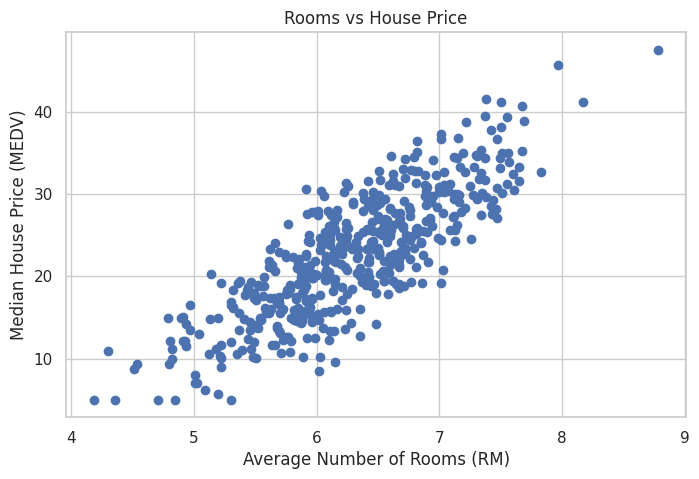

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df_cleaned['RM'], df_cleaned['MEDV'])

plt.title("Rooms vs House Price")
plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("Median House Price (MEDV)")

plt.show()

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 403
Testing Samples: 101


In [15]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

print("\nRegression Equation:")
print(f"MEDV = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * RM)")

Intercept: -35.18205307766411
Slope: 9.18510447590031

Regression Equation:
MEDV = -35.18 + (9.19 * RM)


In [16]:
y_pred = model.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred.round(2)
})

display(comparison_df.head(10))

,Actual Price,Predicted Price
0,21.11,16.53
1,27.72,25.81
2,13.50,10.47
3,20.72,22.22
4,29.50,24.15
5,30.28,29.48
6,27.79,30.77
7,22.97,26.54
8,27.97,23.42
9,36.71,29.21


In [17]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.6597500522282886
MSE: 17.23312287092897
RMSE: 4.1512796666725515
R2 Score: 0.6708160770712648


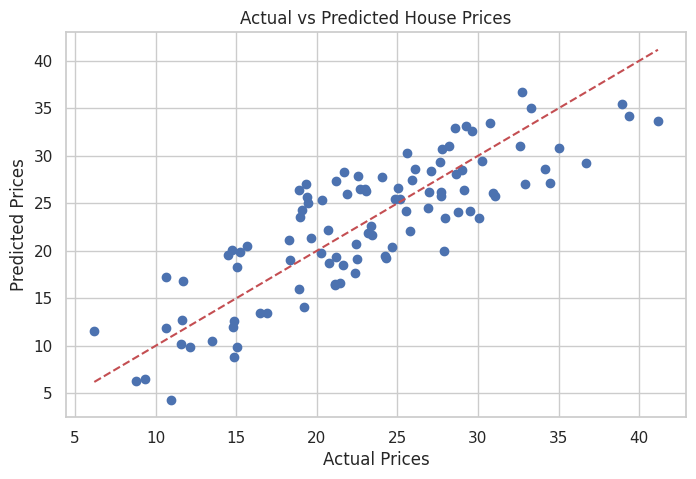

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")

plt.show()

In [19]:
new_rooms = pd.DataFrame({'RM': [7.0]})

new_pred = model.predict(new_rooms)

print("Number of Rooms:", 7.0)
print("Predicted House Price:", round(new_pred[0], 2), "($1000s)")
print("Price in Dollars:", round(new_pred[0] * 1000, 2))

Number of Rooms: 7.0
Predicted House Price: 29.11 ($1000s)
Price in Dollars: 29113.68
